In [215]:
# SCRIPT ASSUMPTIONS
"""This script assumes the node1/og_node pick file, node2/calib_node pick file, and distance
file all have the same number of lines, in matching shot order (row i in
every file = the same physical shot). No grouping/iteration by repeat-shot
sets is done -- row order alone is the link between files.
A simple length check is still included below, since a silent length
mismatch would misalign every row after the point of divergence.
Does not include assumptions explicitly 5-impacts per transect locations
to avoid potential diffculties if any given strike is intentionally not 
included."""

'This script assumes the node1/og_node pick file, node2/calib_node pick file, and distance\nfile all have the same number of lines, in matching shot order (row i in\nevery file = the same physical shot). No grouping/iteration by repeat-shot\nsets is done -- row order alone is the link between files.\nA simple length check is still included below, since a silent length\nmismatch would misalign every row after the point of divergence.\nDoes not include assumptions explicitly 5-impacts per transect locations\nto avoid potential diffculties if any given strike is intentionally not \nincluded.'

In [4]:
# 1.a. clean the snuffler marker files
# gets rid of station info
# creates just the list of dates and times without replacing original file

input_file = r"D:\arrival_markers\C2511\C2511_snuffler_markers.txt"
output_file = r"D:\arrival_markers\C2511\C2511_markers_clean_new.txt"

with open(input_file) as fin, open(output_file, "w") as fout:
    for line in fin:
        parts = line.split()
        if len(parts) >= 2:
            fout.write(f"{parts[0]} {parts[1]}\n")

In [221]:
# 1.b. re-constructs the Snuffler marker file format from the cleaned file formats

input_file = r"D:\arrival_markers\2511\2511_hammer_markers_clean.txt"
output_file = r"D:arrival_markers\2511\2511_snuffler_hammer_later_arrivals_reconstructed.txt"

header = "# Snuffler Markers File Version 0.2\n"
#suffix = "0 SS.05764.SW.GPZ" # calibration node station ID code
suffix = "0  SS.18943.SW.GPZ" # replace with orig_node station ID code

with open(input_file) as fin, open(output_file, "w") as fout:
    fout.write(header)
    for line in fin:
        line = line.strip()
        if not line:
            continue
        fout.write(f"{line}  {suffix}\n")


In [216]:
# 2. compute dt

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# computing dt
og_node_t = pd.read_csv(r"D:\arrival_markers\2511\2511_rock_markers_clean_newest.txt", skiprows=1, header=None, names=["t1"])
calib_node_t = pd.read_csv(r"D:\arrival_markers\C2511\C2511_rock_markers_clean_newest.txt", skiprows=1, header=None, names=["t2"])

og_node_t["t1"] = pd.to_datetime(og_node_t["t1"])
calib_node_t["t2"] = pd.to_datetime(calib_node_t["t2"])

dt = (og_node_t["t1"] - calib_node_t["t2"]).dt.total_seconds()

print("dt (seconds), first few shots:")
print(dt.head())

dt (seconds), first few shots:
0   -0.055965
1   -0.017989
2   -0.020944
3   -0.014971
4   -0.012950
dtype: float64


In [202]:
# 3. compute dx
transect_x = 44.2 # transect length (meters) # check what N11's was

og_node_x = pd.read_csv(r"D:\arrival_markers\arrival_dx\N11_rock_dx.txt",
                 header=None, names=["x1"]) # impact locations from field notes

print(og_node_x.head())

calib_node_x = pd.DataFrame({"x2": transect_x - og_node_x["x1"]})

# vector length check
n_t1, n_t2, n_x = len(og_node_t), len(calib_node_t), len(og_node_x)
print(f"length of node1_t: {n_t1} | length of node2_t: {n_t2} | length of distances: {n_x}")

# turn this into an if statement in full pipeline
assert n_t1 == n_t2 == n_x, (
    f"Line count mismatch (node1={n_t1}, node2={n_t2}, distances={n_x}). "
    f"These three files must correspond line-for-line -- find and fix "
    f"the mismatch before proceeding, since every row after the "
    f"divergence point would otherwise be silently misaligned."
)
print("Line counts match -- proceeding.\n")


# compute dx

dx = og_node_x["x1"] - calib_node_x["x2"]

dx.to_csv(r"D:\arrival_markers\arrival_dx\C2511_x.txt",
         index=False, header=None)

print("dx (meters), first few shots:")
print(dx.head())

     x1
0   6.0
1   8.3
2  10.0
3  12.0
4  14.0
length of node1_t: 20 | length of node2_t: 20 | length of distances: 20
Line counts match -- proceeding.

dx (meters), first few shots:
0   -32.2
1   -27.6
2   -24.2
3   -20.2
4   -16.2
dtype: float64



Per-shot velocity (dx/dt), first few shots:
0      575.357688
1     1534.257468
2     1155.442490
3     1349.230745
4     1250.924584
5     1018.440195
6     1648.609368
7     2138.652944
8     -101.803500
9      420.437233
10     960.439020
11    1088.564013
12    1146.733911
13     772.863461
14    1034.119688
15     955.472960
16     504.978503
17     547.512181
18     712.960943
19     745.879285
dtype: float64


<Figure size 1200x800 with 0 Axes>

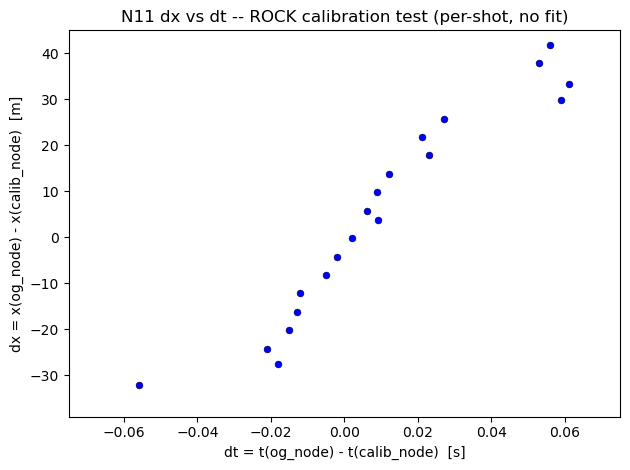

In [203]:
# compute p-wave velocity
# computed per-shot, no averaging
from matplotlib.ticker import AutoMinorLocator, MultipleLocator

v_per_shot = dx / dt
print("\nPer-shot velocity (dx/dt), first few shots:")
print(v_per_shot)#.head())

plt.figure(figsize=(12, 8))
fig, ax = plt.subplots()
# ax.xaxis.set_major_locator(MultipleLocator(0.005))
# ax.xaxis.set_major_formatter('{x:.0f}')
ax.scatter(dt, dx, color="blue", s=25, edgecolors="k", linewidths=0.3)
plt.ylim(-39, 45)
plt.xlim(-0.075, 0.075)
plt.xlabel("dt = t(og_node) - t(calib_node)  [s]")
plt.ylabel("dx = x(og_node) - x(calib_node)  [m]")
plt.title("N11 dx vs dt -- ROCK calibration test (per-shot, no fit)")
plt.tight_layout()
#plt.savefig(r"D:\arrival_markers\arrival_plots\N11_hammer_dx_vs_dt_pershot.png", dpi=150)
plt.show()




# def v_p(L, og_node_x, og_node_t, calib_node_t):
#     """Function to compute the p-wave velocity
#     of hammer or rock strike impacts"""
#     # change the variables in this to these names
#     # L = total length of transect
#     # x1 = distance from strike to node1/og_node
#     # x2 = distance from strike to node2/calib_node
#     # t1 = p-wave travel time from strike to node1/og_node
#     # t2 = p-wave travel time from strike to node2/calib_node

#     # v_p = dx/dt = (x2 - x1)/(t2 - t1) = ((L - x1) - x1)/(t2 - t1)
    
#     vel_p = (L - 2*og_node_x) / (og_node_t - calib_node_t)
#     vel_p = (L - 2*x1) / (t2 - t1) # re-written with preferred variable names
#     return vel_p

n=== OUTLIER CHECK ===
QC fit (for residuals only): slope=710.465 m/s, intercept=-2.171408 m
Median residual: 0.0629 m | MAD: 5.4836 m
Flagging threshold: 1.75 MADs

3 shot(s) flagged for review in Snuffler (sorted worst first):

 shot_index                    t1_og_node                 t2_calib_node  dist_og_node  dist_calib_node    dt_sec  dx_m  residual_m  mod_z_score
          1 2025-10-23 22:31:26.711023808 2025-10-23 22:31:26.729012966           8.3             35.9 -0.017989 -27.6  -12.647919     2.317964
         16 2025-10-23 22:36:52.581000805 2025-10-23 22:36:52.521988392          37.0              7.2  0.059012  29.8   -9.954865     1.826853
          0 2025-10-23 22:31:05.901042461 2025-10-23 22:31:05.957007647           6.0             38.2 -0.055965 -32.2    9.732732     1.763418

Saved flagged shot details to N11_flagged_outlier_shots.csv for reference while reviewing in Snuffler.


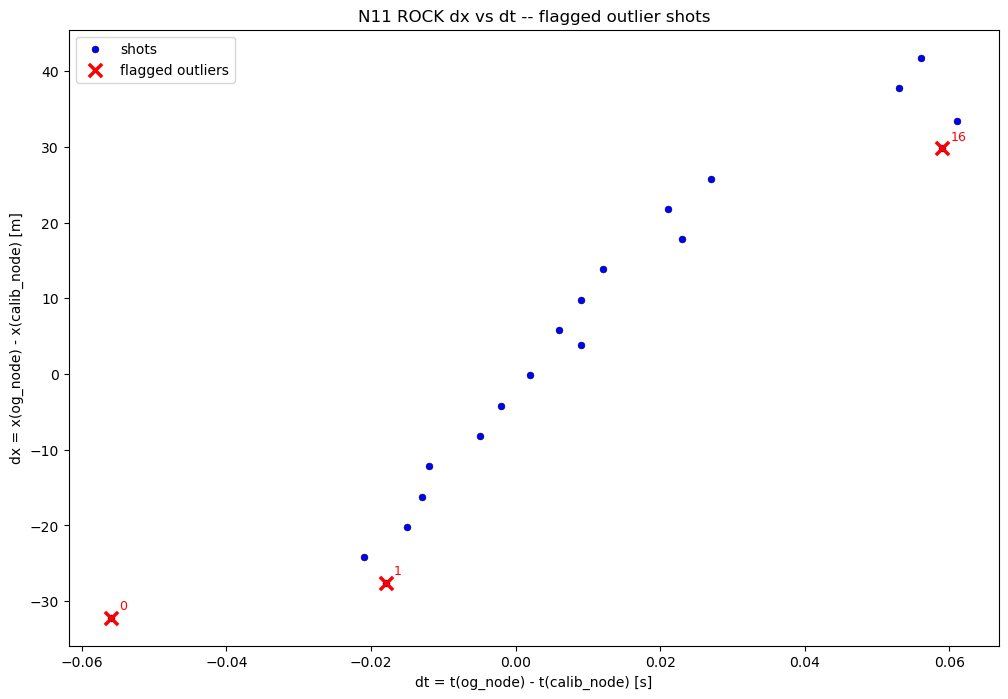

In [217]:
# residual tracking
# uses median + median absolute deviation (since outliers would inflate mean + SD)
# builds table of outlier timestamps, stances, dt, and dx, residual size, and MAD "z-score"
# median scores instead of means so values are not thrown off by outliers themselves
# NOT for final calibration velocity, this is for flagging and re-assessing arrival picks in snuffler before continuing analysis

# decide z-score treshold, standard is ~3.5

# fit line through inital arrival picks
slope_qc, intercept_qc = np.polyfit(dt, dx, 1)
predicted_dx = slope_qc * dt + intercept_qc
residuals = dx - predicted_dx

median_resid = residuals.median()
mad_resid = (residuals - median_resid).abs().mean()

# avoiding some 0/0 division, checks and sets those to lim-->0
if mad_resid == 0:
    mad_resid = residuals.abs().meadian()
    if mad_resid == 0:
        mad_resid = 1e-9

# median and median absolute deviation (MAD) threshold
# shots with |residual - median| > 3.5 MADS are flagged -- akin to 3 SD for mean-based distributions
mad_threshold = 1.75

modified_z = (residuals - median_resid).abs() / mad_resid
outlier = modified_z > mad_threshold

# QC table to find outlier shots
qc_table = pd.DataFrame({
    "shot_index": np.arange(len(dt)),
    "t1_og_node": og_node_t["t1"],
    "t2_calib_node": calib_node_t["t2"],
    "dist_og_node": og_node_x["x1"],
    "dist_calib_node": calib_node_x["x2"],
    "dt_sec": dt,
    "dx_m": dx,
    "residual_m": residuals,
    "mod_z_score": modified_z,
})

flagged = qc_table[outlier].sort_values("mod_z_score", ascending=False)

print(f"n=== OUTLIER CHECK ===")
print(f"QC fit (for residuals only): slope={slope_qc:.3f} m/s, "
      f"intercept={intercept_qc:3f} m")
print(f"Median residual: {median_resid:.4f} m | MAD: {mad_resid:.4f} m")
print(f"Flagging threshold: {mad_threshold} MADs")

if len(flagged) == 0:
    print("\nNo shots flagged -- all points sit reasonably close to the overall linear trend.")
    
else:
    print(f"\n{len(flagged)} shot(s) flagged for review in Snuffler "
          f"(sorted worst first):\n")
    # print full rows without pandas truncating timestamp/float columns
    # to read off exact values for easier searching
    with pd.option_context("display.max_columns", None,
                           "display.width", None):
        print(flagged.to_string(index=False))
    flagged.to_csv(r"D:\arrival_markers\arrival_plots\N11_rock_flagged_outlier_shots.csv", index=False)

    print(f"\nSaved flagged shot details to "
          f"N11_flagged_outlier_shots.csv for reference while reviewing in Snuffler.")


# highlight outlier in plot for viewability
plt.figure(figsize=(12,8))
plt.scatter(dt, dx, color="blue", s=25, edgecolors="k", linewidths=0.3, label="shots")

if len(flagged) > 0:
    plt.scatter(flagged["dt_sec"], flagged["dx_m"], color="red", s=90, marker="x", linewidths=2.5, label="flagged outliers")
    # annotate each flagged point with shot index (row number) for easy matching from plot to saved tabled
    for _, r in flagged.iterrows():
        plt.annotate(str(int(r["shot_index"])),
                     (r["dt_sec"], r["dx_m"]),
                     textcoords="offset points", xytext=(6,6),
                     fontsize=9, color="red")

plt.xlabel("dt = t(og_node) - t(calib_node) [s]")
plt.ylabel("dx = x(og_node) - x(calib_node) [m]")
plt.title("N11 ROCK dx vs dt -- flagged outlier shots")
plt.legend()
plt.tight_layout
#plt.savefig(r"D:\arrival_markers\arrival_plots\N11_rock_arrvials_flagged.png", dpi=200)
plt.show()


In [205]:
# local slope consistency check
# catch points that hide themselves in global residual/fit
# if local pair implies wildly different velocity than global trend
# OR
# if dt and dx are not both increasing/decreasing together for a pair (sign inconsistency)
# strong indicator that arrival pick is wrong

# OUTPUT
# for each pair of shots adjacent in dx, this prints:
# - the 2 shot indicies involed
# - the implied LOCAL velocity between just the 2 points
# - how that compares to global fit slope
# - a flag if dt actually decreased while dx increased (or vice versa)
# --- an ordering inconsistency that is physically impossible under a relatively constant velocity
#     and is a much stronger indicator than 'residual in big'


# sort by dx so "neighboring" means physically adjacent along transect (not in time or file order)
sorted_qc = qc_table.sort_values("dx_m").reset_index(drop=True)

local_rows = []
for i in range(len(sorted_qc) - 1):
    row_a = sorted_qc.iloc[i]
    row_b = sorted_qc.iloc[i + 1]

    ddx = row_b["dx_m"] - row_a["dx_m"]
    ddt = row_b["dt_sec"] - row_a["dt_sec"]

    # avoid dividing by zero againn(shots with same dt)
    if ddt == 0:
        local_velocity = np.nan
    else:
        local_velocity = ddx/ddt

    # ording inconsistency: dx increase but dt didn't (0 or decreased)
    # larger dx should always correspond to larger dt
    ordering_ok = (ddx > 0 and ddt > 0) or (ddx < 0 and ddt < 0)

    local_rows.append({
        "shot_a_index": int(row_a["shot_index"]),
        "shot_b_index": int(row_b["shot_index"]),
        "dx_a": row_a["dx_m"],
        "dx_b": row_b["dx_m"],
        "dt_a": row_a["dt_sec"],
        "dt_b": row_b["dt_sec"],
        "local_vel": local_velocity,
        "order_consistent": ordering_ok})

local_df = pd.DataFrame(local_rows)

# compare local velocity to global fit slope
# tracks very different local velocities or incorrect sign changes
# very different local velocity determined by: local velocity less than half or more than double global slope
# can tune this threshold
local_df["ratio_to_global_slope"] = local_df["local_vel"]/slope_qc

# flag
local_df["flag_ordering_violation"] = ~local_df["order_consistent"]
local_df["flag_slope_deviation"] = (
    (local_df["ratio_to_global_slope"] < 0.5) |
    (local_df["ratio_to_global_slope"] > 2.0) |
    (local_df["local_vel"] < 0)
)

flagged_local = local_df[local_df["flag_ordering_violation"] | local_df["flag_slope_deviation"]]

print(f"\n=== LOCAL SLOPE CONSISTENCY CHECK ===")
print(f"Global fit slope: {slope_qc:.3f} m/s")

if len(flagged_local) == 0:
    print("\nNo locally-inconsistent neighboring paris found.")
else:
    print(f"\n{len(flagged_local)} neighboring shot pair(s) flagged:\n")
    with pd.option_context("display.max_columns", None,
                           "display.width", None):
        print(flagged_local.to_string(index=False))

# remember flagged pair may just be bc of ONE node, not both erroring
# count how often each individual shot index appears across all flagged pairs
# a shot appearing in multiple flagged pairs (eg flagged against both its dx-neighbors)
# is a stronger candidate for being the actual bad pick, vs a shot that only appears once (where its NEIGHBOR might be the problem instead)

# i dont think this next part is necessary, can usually tell which node is the problem visually

# from collections import Counter
# involved_shots = list(flagged_local["shot_a_index"]) + \
#                     list(flagged_local["shot_b_index"])
# shot_flag_counts = Counter(involved_shots)

# print(f"\nShot indices appearing in flagged pairs (higher count = "
#           f"stronger candidate for being the actual bad pick, since it "
#           f"conflicts with more than one neighbor):")
#     for shot_idx, count in sorted(shot_flag_counts.items(),
#                                     key=lambda x: -x[1]):
#         shot_row = qc_table[qc_table["shot_index"] == shot_idx].iloc[0]
#         print(f"  shot {shot_idx}  (flagged in {count} pair(s))  "
#               f"t1={shot_row['t1_node1']}  t2={shot_row['t2_node2']}  "
#               f"dist_node1={shot_row['dist_node1_m']}  "
#               f"dt={shot_row['dt_sec']:.6f}  dx={shot_row['dx_m']:.2f}")


=== LOCAL SLOPE CONSISTENCY CHECK ===
Global fit slope: 710.465 m/s

9 neighboring shot pair(s) flagged:

 shot_a_index  shot_b_index  dx_a  dx_b      dt_a      dt_b    local_vel  order_consistent  ratio_to_global_slope  flag_ordering_violation  flag_slope_deviation
            0             1 -32.2 -27.6 -0.055965 -0.017989   121.129045              True               0.170493                    False                  True
            1             2 -27.6 -24.2 -0.017989 -0.020944 -1150.514737             False              -1.619382                     True                  True
            3             4 -20.2 -16.2 -0.014971 -0.012950  1979.146721              True               2.785705                    False                  True
            4             5 -16.2 -12.2 -0.012950 -0.011979  4118.115797              True               5.796364                    False                  True
            9            10   3.8   5.8  0.009038  0.006039  -666.821147             Fal

In [206]:
# sort by dx so "neighboring" means physically adjacent along the
# transect, not adjacent in time or file order
sorted_qc = qc_table.sort_values("dx_m").reset_index(drop=True)

local_rows = []
for i in range(len(sorted_qc) - 1):
    row_a = sorted_qc.iloc[i]
    row_b = sorted_qc.iloc[i + 1]

    ddx = row_b["dx_m"] - row_a["dx_m"]
    ddt = row_b["dt_sec"] - row_a["dt_sec"]

    # an ordering inconsistency: dx increased but dt did NOT increase
    # (stayed flat or went down), or dx decreased but dt did NOT decrease.
    # Under a real, constant, positive velocity, this should never happen.
    ordering_ok = (ddx > 0 and ddt > 0) or (ddx < 0 and ddt < 0) or (ddx == 0 and ddt == 0)

    local_rows.append({
        "shot_a_index": int(row_a["shot_index"]),
        "shot_b_index": int(row_b["shot_index"]),
        "t1_og_node_a": row_a["t1_og_node"], "t1_og_node_b": row_b["t1_og_node"],
        "t2_calib_node_a": row_a["t2_calib_node"], "t2_calib_node_b": row_b["t2_calib_node"],
        "dist_og_node_a": row_a["dist_og_node"], "dist_og_node_b": row_b["dist_og_node"],
        "dist_calib_node_a": row_a["dist_calib_node"], "dist_calib_node_b": row_b["dist_calib_node"],
        "dx_a": row_a["dx_m"], "dx_b": row_b["dx_m"],
        "dt_a": row_a["dt_sec"], "dt_b": row_b["dt_sec"],
        "order_consistent": ordering_ok,
    })

local_df = pd.DataFrame(local_rows)
flagged_local = local_df[~local_df["order_consistent"]]

print(f"\n=== LOCAL ORDERING CONSISTENCY CHECK ===")

if len(flagged_local) == 0:
    print("\nNo ordering violations found between neighboring shots.")
else:
    print(f"\n{len(flagged_local)} neighboring shot pair(s) with an "
          f"ordering violation (dx and dt did not move in the same "
          f"direction, which is physically impossible under constant "
          f"positive velocity):\n")

    for _, r in flagged_local.iterrows():
        print(f"--- shot {r['shot_a_index']}  vs  shot {r['shot_b_index']} ---")
        print(f"  dx_a = {r['dx_a']:.2f} m   dx_b = {r['dx_b']:.2f} m   "
              f"(dx {'increased' if r['dx_b'] > r['dx_a'] else 'decreased'})")
        print(f"  dt_a = {r['dt_a']:.6f} s   dt_b = {r['dt_b']:.6f} s   "
              f"(dt {'increased' if r['dt_b'] > r['dt_a'] else 'decreased'})")
        print(f"  og_node (t1) times    -- shot_a: {r['t1_og_node_a']}   "
              f"shot_b: {r['t1_og_node_b']}")
        print(f"  calib_node (t2) times -- shot_a: {r['t2_calib_node_a']}   "
              f"shot_b: {r['t2_calib_node_b']}")
        print(f"  og_node distances     -- shot_a: {r['dist_og_node_a']}   "
              f"shot_b: {r['dist_og_node_b']}")
        print(f"  calib_node distances  -- shot_a: {r['dist_calib_node_a']}   "
              f"shot_b: {r['dist_calib_node_b']}")
        print()

    # flagged_local.to_csv(
    #     r"D:\arrival_markers\arrival_plots\N11_flagged_local_inconsistencies.csv",
    #     index=False
    # )
    # print(f"Saved full details to N11_flagged_local_inconsistencies.csv")


=== LOCAL ORDERING CONSISTENCY CHECK ===

4 neighboring shot pair(s) with an ordering violation (dx and dt did not move in the same direction, which is physically impossible under constant positive velocity):

--- shot 1  vs  shot 2 ---
  dx_a = -27.60 m   dx_b = -24.20 m   (dx increased)
  dt_a = -0.017989 s   dt_b = -0.020944 s   (dt decreased)
  og_node (t1) times    -- shot_a: 2025-10-23 22:31:26.711023808   shot_b: 2025-10-23 22:31:42.918065071
  calib_node (t2) times -- shot_a: 2025-10-23 22:31:26.729012966   shot_b: 2025-10-23 22:31:42.939009428
  og_node distances     -- shot_a: 8.3   shot_b: 10.0
  calib_node distances  -- shot_a: 35.900000000000006   shot_b: 34.2

--- shot 9  vs  shot 10 ---
  dx_a = 3.80 m   dx_b = 5.80 m   (dx increased)
  dt_a = 0.009038 s   dt_b = 0.006039 s   (dt decreased)
  og_node (t1) times    -- shot_a: 2025-10-23 22:34:20.377031088   shot_b: 2025-10-23 22:34:32.918040276
  calib_node (t2) times -- shot_a: 2025-10-23 22:34:20.367992878   shot_b: 20


Shots highlighted on plot (appearing in an ordering-violation pair), with how many flagged pairs each appears in (higher = stronger candidate for the actual bad pick):
  shot 1: flagged in 1 pair(s)
  shot 9: flagged in 1 pair(s)
  shot 13: flagged in 1 pair(s)
  shot 17: flagged in 1 pair(s)
  shot 2: flagged in 1 pair(s)
  shot 10: flagged in 1 pair(s)
  shot 14: flagged in 1 pair(s)
  shot 18: flagged in 1 pair(s)


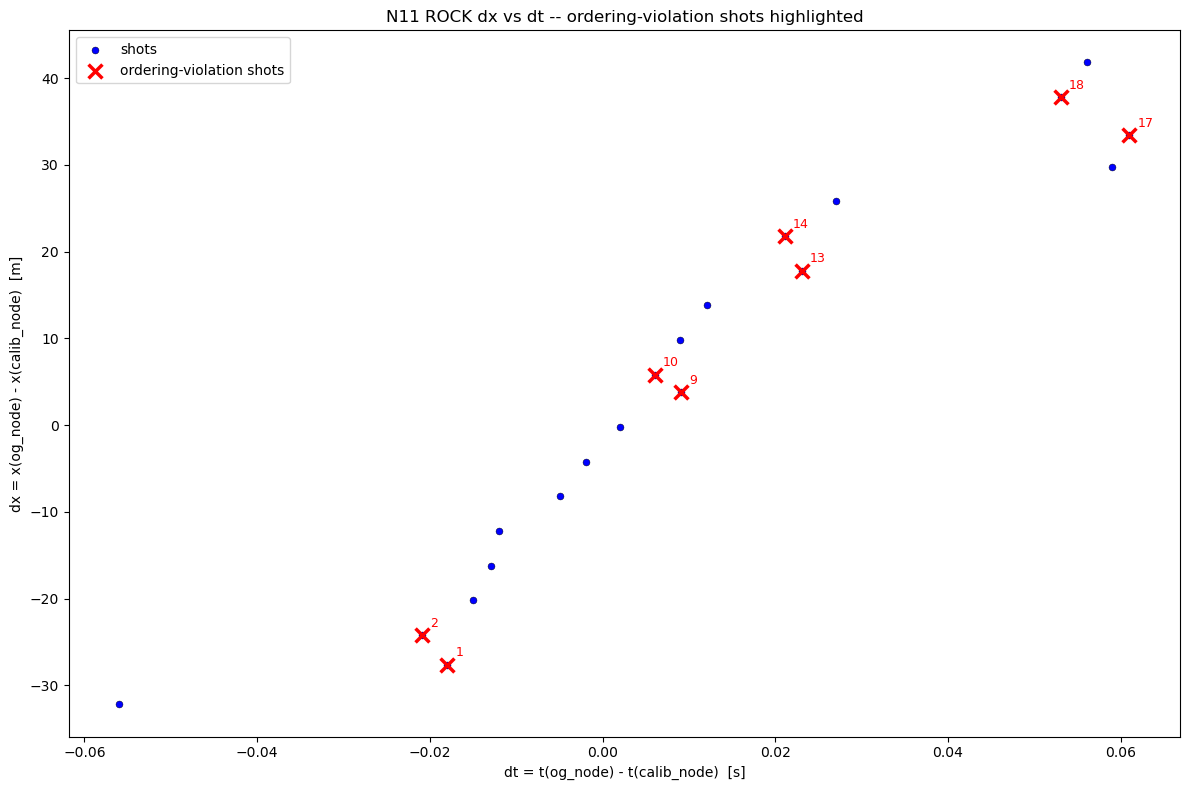

In [207]:
if len(flagged_local) > 0:
    # collect every shot index involved in any flagged pair, along with
    # how many flagged pairs each one appears in
    from collections import Counter
    involved_shots = list(flagged_local["shot_a_index"]) + \
                      list(flagged_local["shot_b_index"])
    shot_flag_counts = Counter(involved_shots)

    highlighted_indices = list(shot_flag_counts.keys())
    highlighted_rows = qc_table[
        qc_table["shot_index"].isin(highlighted_indices)
    ]

    print(f"\nShots highlighted on plot (appearing in an ordering-"
          f"violation pair), with how many flagged pairs each appears in "
          f"(higher = stronger candidate for the actual bad pick):")
    for shot_idx, count in sorted(shot_flag_counts.items(), key=lambda x: -x[1]):
        print(f"  shot {shot_idx}: flagged in {count} pair(s)")
else:
    highlighted_rows = qc_table.iloc[0:0]  # empty, nothing to highlight

plt.figure(figsize=(12, 8))
plt.scatter(dt, dx, color="blue", s=25, edgecolors="k", linewidths=0.3,
            label="shots")

if len(highlighted_rows) > 0:
    plt.scatter(highlighted_rows["dt_sec"], highlighted_rows["dx_m"],
                color="red", s=100, marker="x", linewidths=2.5,
                label="ordering-violation shots")
    # annotate each highlighted point with its shot index so it's easy
    # to match back to the printed output / CSV
    for _, r in highlighted_rows.iterrows():
        plt.annotate(str(int(r["shot_index"])),
                     (r["dt_sec"], r["dx_m"]),
                     textcoords="offset points", xytext=(6, 6),
                     fontsize=9, color="red")

plt.xlabel("dt = t(og_node) - t(calib_node)  [s]")
plt.ylabel("dx = x(og_node) - x(calib_node)  [m]")
plt.title("N11 ROCK dx vs dt -- ordering-violation shots highlighted")
plt.legend()
plt.tight_layout()
#plt.savefig(r"D:\arrival_markers\arrival_plots\N11_hammer_dx_vs_dt_ordering_flagged.png", dpi=150)
plt.show()

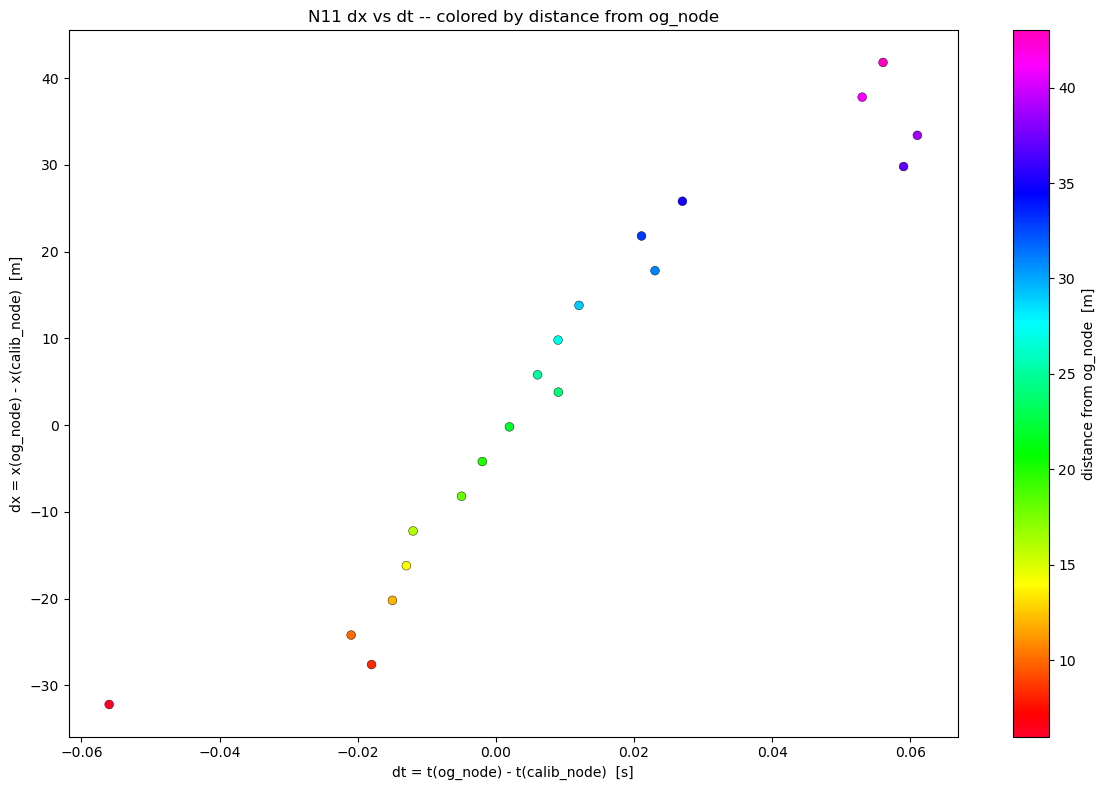

In [208]:
plt.figure(figsize=(12,8))
sc = plt.scatter(dt, dx, c=qc_table["dist_og_node"], cmap="gist_rainbow", s=40, edgecolors="k", linewidth=0.3)
cbar = plt.colorbar(sc)
cbar.set_label("distance from og_node  [m]")

plt.xlabel("dt = t(og_node) - t(calib_node)  [s]")
plt.ylabel("dx = x(og_node) - x(calib_node)  [m]")
plt.title("N11 dx vs dt -- colored by distance from og_node")
plt.tight_layout()
#plt.savefig(r"D:\arrival_markers\arrival_plots\N11_hammer_dx_vs_dt_colorgradient.png",dpi=150)
plt.show()

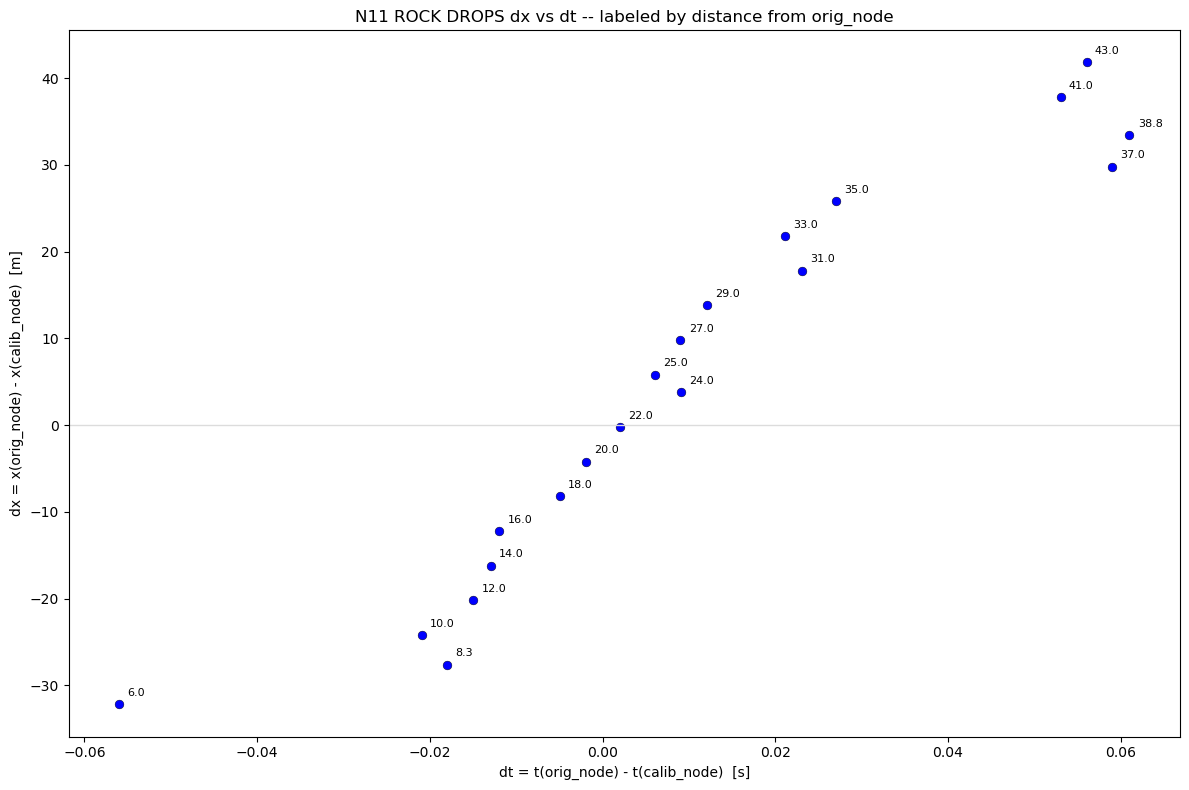

In [209]:
plt.figure(figsize=(12, 8))
sc = plt.scatter(dt, dx, color="blue", s=40, edgecolors="k", linewidths=0.3, label="distance from og_node")
plt.axhline(y=0, color='gainsboro', linewidth=1)

# cbar = plt.colorbar(sc)
# cbar.set_label("distance from og_node  [m]")

# label each point directly with its actual distance-from-og_node value
for _, r in qc_table.iterrows():
    plt.annotate(f"{r['dist_og_node']:.1f}",
                 (r["dt_sec"], r["dx_m"]),
                 textcoords="offset points", xytext=(6, 6),
                 fontsize=8, color="black")
plt.xlabel("dt = t(orig_node) - t(calib_node)  [s]")
plt.ylabel("dx = x(orig_node) - x(calib_node)  [m]")
plt.title("N11 ROCK DROPS dx vs dt -- labeled by distance from orig_node")
plt.tight_layout()
#plt.savefig(r"D:\arrival_markers\arrival_plots\N11_hammer_dx_vs_dt_colorgradient.png",dpi=150)
plt.show()

In [212]:
#2025-10-23 22:34:20.376964808 this is what i think C2511 marker should be, trying different

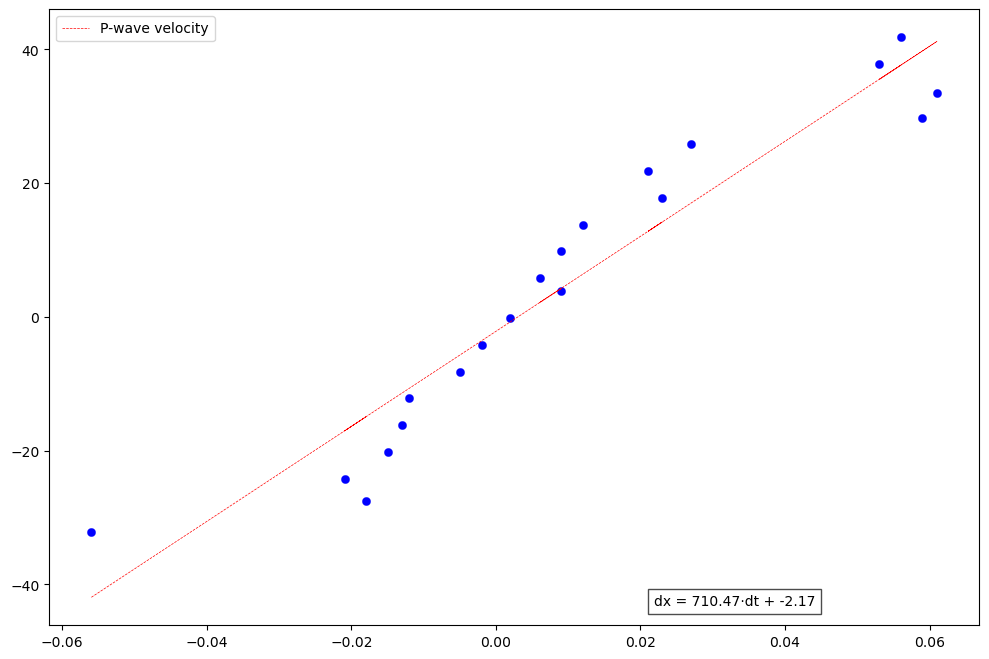

y = mx + b => dx = slope*dt + intercept => dx = 710.465323486201*dt + -2.171408175778076
slope = avg velocity: 710.465323486201
intercept: -2.171408175778076
    dist_og_node      dx_m          dt_sec                  v_p
0            6.0     -32.2       -0.055965           575.357688
1            8.3     -27.6       -0.017989          1534.257468
2           10.0     -24.2       -0.020944          1155.442490
3           12.0     -20.2       -0.014971          1349.230745
4           14.0     -16.2       -0.012950          1250.924584
5           16.0     -12.2       -0.011979          1018.440195
6           18.0      -8.2       -0.004974          1648.609368
7           20.0      -4.2       -0.001964          2138.652944
8           22.0      -0.2        0.001965          -101.803500
9           24.0       3.8        0.009038           420.437233
10          25.0       5.8        0.006039           960.439020
11          27.0       9.8        0.009003          1088.564013
12        

In [213]:
# compute slope of best fit line
plt.figure(figsize=(12,8))
slope, intercept = np.polyfit(dt, dx, 1)
plt.scatter(dt, dx, color="blue", linewidth=0.2)
plt.plot(dt, slope*dt + intercept, color='red', linestyle='--', linewidth=0.5, label='P-wave velocity')
#plt.text(0.65, 0.05, f'dx = {slope:.2f}dt + {intercept:.2f}', size=10)
plt.text(0.65, 0.05, f"dx = {slope:.2f}·dt + {intercept:.2f}",
          transform=plt.gca().transAxes, va="top", fontsize=10,
          bbox=dict(facecolor="white", alpha=0.7))
plt.legend()
plt.show()
print(f"y = mx + b => dx = slope*dt + intercept => dx = {slope}*dt + {intercept}")
print(f"slope = avg velocity: {slope}")
print(f"intercept: {intercept}")
p_velocity = dx/dt
#print(f"p-wave velocities:\n {p_velocity}")

import pandas as pd
dx_dt_table = pd.DataFrame({
    "dist_og_node": og_node_x["x1"],
    "   ": " ",
    "dx_m": dx,
    "     ": " ",
    "dt_sec": dt,
    "       ": " ",
    "v_p": p_velocity,
})
print(dx_dt_table)
print("\n")
vel_p = (transect_x - 2*og_node_x["x1"]) / -dt
print(f"another vel_p: {vel_p}")

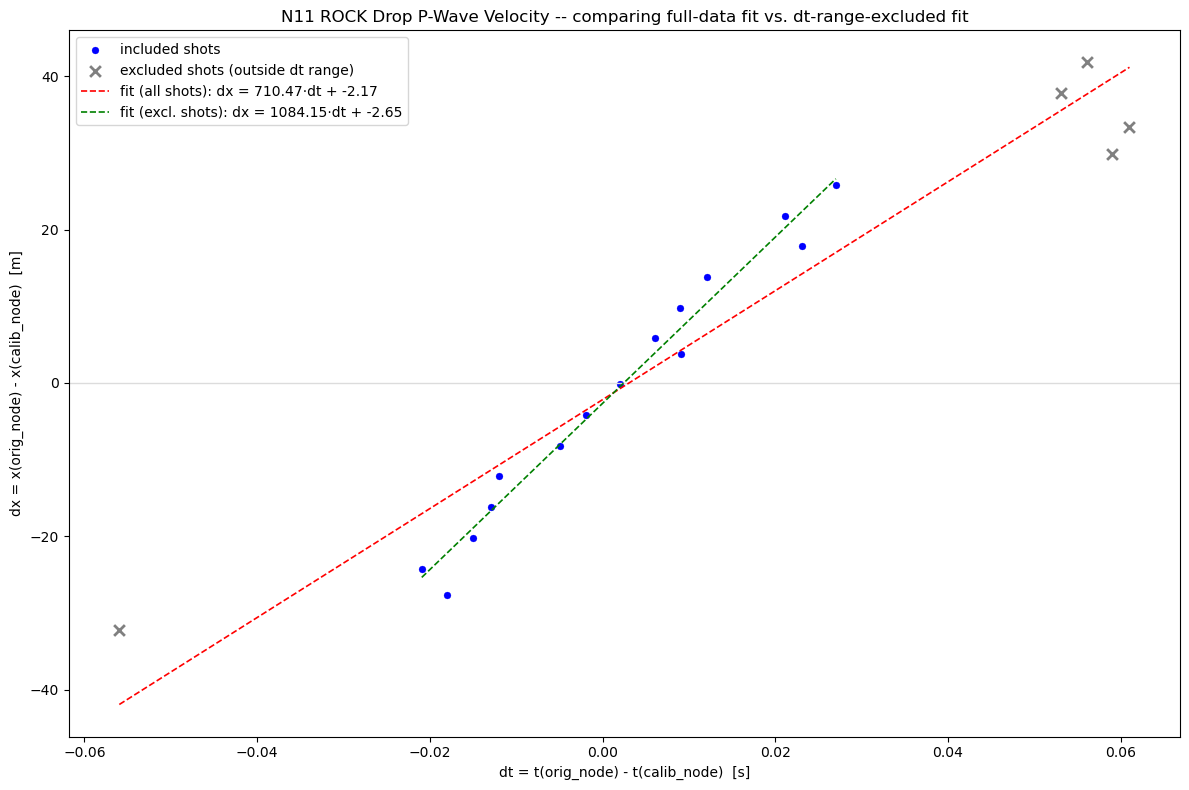

FULL-DATA FIT: per-shot table
 dist_og_node      dx_m          dt_sec                 v_p
          6.0     -32.2       -0.055965          575.357688
          8.3     -27.6       -0.017989         1534.257468
         10.0     -24.2       -0.020944         1155.442490
         12.0     -20.2       -0.014971         1349.230745
         14.0     -16.2       -0.012950         1250.924584
         16.0     -12.2       -0.011979         1018.440195
         18.0      -8.2       -0.004974         1648.609368
         20.0      -4.2       -0.001964         2138.652944
         22.0      -0.2        0.001965         -101.803500
         24.0       3.8        0.009038          420.437233
         25.0       5.8        0.006039          960.439020
         27.0       9.8        0.009003         1088.564013
         29.0      13.8        0.012034         1146.733911
         31.0      17.8        0.023031          772.863461
         33.0      21.8        0.021081         1034.119688
         3

In [214]:
import numpy as np
import matplotlib.pyplot as plt

# fit 1: all points, no exclusion
slope_all, intercept_all = np.polyfit(dt, dx, 1)

# fit 2: excluding points outside a chosen dt range
dt_lower, dt_upper = -0.05, 0.05 # set exclusion bounds

mask = (dt > dt_lower) & (dt < dt_upper)
dt_fit = dt[mask]
dx_fit = dx[mask]

slope_excl, intercept_excl = np.polyfit(dt_fit, dx_fit, 1)

# --- plot ---
plt.figure(figsize=(12, 8))

# all points, in blue -- points excluded from fit 2 are marked separately
plt.scatter(dt[mask], dx[mask], color="blue", s=25, linewidth=0.2,
            label="included shots")
plt.scatter(dt[~mask], dx[~mask], color="gray", s=60, marker="x",
            linewidths=2, label="excluded shots (outside dt range)")
plt.axhline(y=0, color='gainsboro', linewidth=1)

# fit line 1: all points (drawn across the full dt range)
dt_line_all = np.linspace(dt.min(), dt.max(), 100)
plt.plot(dt_line_all, slope_all * dt_line_all + intercept_all,
          color="red", linestyle="--", linewidth=1.2,
          label=f"fit (all shots): dx = {slope_all:.2f}·dt + {intercept_all:.2f}")

# fit line 2: excluding chosen dt-range points
# drawn only across the included points' range, so it doesn't
# visually extrapolate beyond where it was actually fit
dt_line_excl = np.linspace(dt_fit.min(), dt_fit.max(), 100)
plt.plot(dt_line_excl, slope_excl * dt_line_excl + intercept_excl,
          color="green", linestyle="--", linewidth=1.2,
          label=f"fit (excl. shots): dx = {slope_excl:.2f}·dt + {intercept_excl:.2f}")

plt.xlabel("dt = t(orig_node) - t(calib_node)  [s]")
plt.ylabel("dx = x(orig_node) - x(calib_node)  [m]")
plt.title("N11 ROCK Drop P-Wave Velocity -- comparing full-data fit vs. dt-range-excluded fit")
plt.legend(loc="best")
plt.tight_layout()
plt.show()

# per-shot v_p
p_velocity = dx / dt

# table 1: all shots
dx_dt_table_all = pd.DataFrame({
    "dist_og_node": og_node_x["x1"],
    "   ": " ",
    "dx_m": dx,
    "     ": " ",
    "dt_sec": dt,
    "       ": " ",
    "v_p": p_velocity,
})
print("FULL-DATA FIT: per-shot table")
print(dx_dt_table_all.to_string(index=False))
print(f"\nFit slope (v_p, all shots): {slope_all:.3f} m/s\n")
print("\n")

# table 2: only shots included in the dt-range-excluded fit
dx_dt_table_excl = pd.DataFrame({
    "dist_og_node": og_node_x["x1"][mask],
    "   ": " ",
    "dx_m": dx[mask],
    "     ": " ",
    "dt_sec": dt[mask],
    "       ": " ",
    "v_p": p_velocity[mask],
})
print("EXCLUDED-ENDS FIT: per-shot table")
print(dx_dt_table_excl.to_string(index=False))
print(f"\nFit slope (v_p, excl. ends): {slope_excl:.3f} m/s")

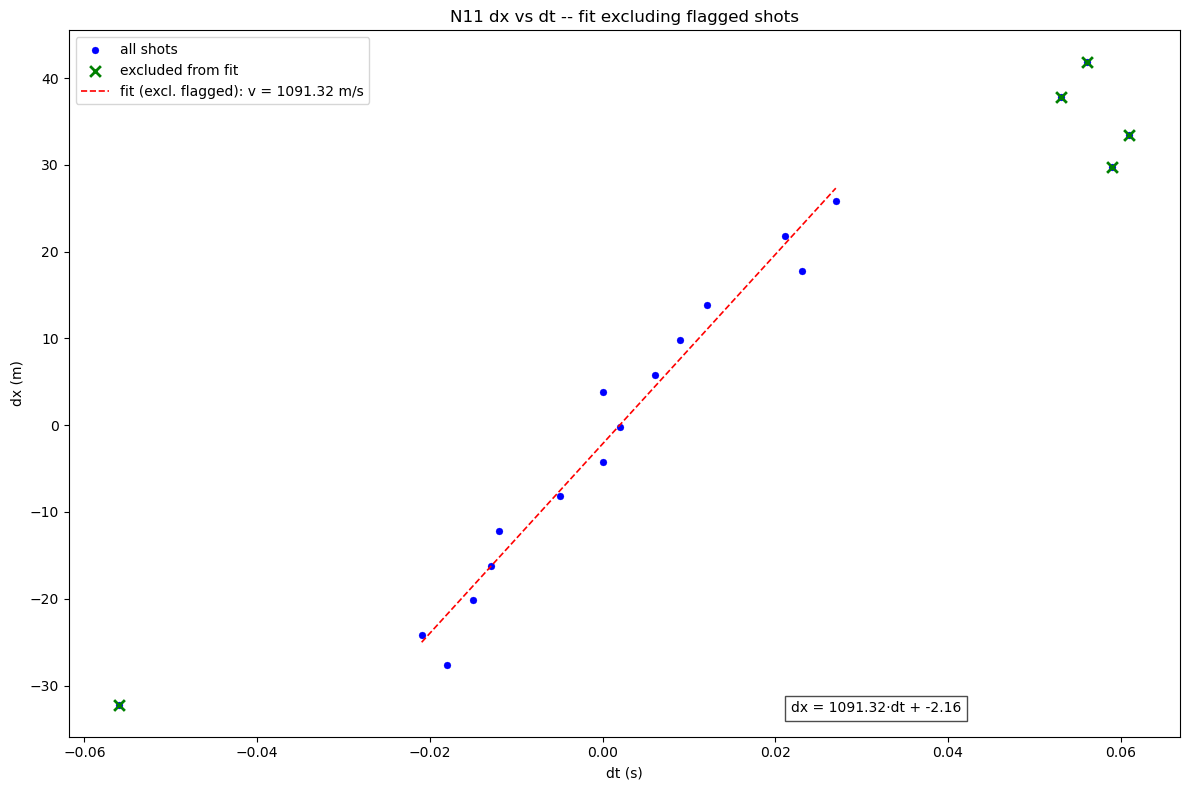

In [165]:
import numpy as np
import matplotlib.pyplot as plt

# --- define which shots to EXCLUDE from the fit ---
# Option A: exclude by index (if you know which shot indices are bad,
# e.g. from your ordering-violation / outlier checks)
# exclude_indices = [0, 18, 19]  # <-- replace with your actual bad shot indices

# mask = ~np.isin(np.arange(len(dt)), exclude_indices)

# Option B (alternative): exclude by value range instead of index,
# e.g. excluding the extreme ends of dt
mask = (dt > -0.04) & (dt < 0.04)

dt_fit = dt[mask]
dx_fit = dx[mask]

# --- fit using only the included (masked) points ---
slope, intercept = np.polyfit(dt_fit, dx_fit, 1)

# --- plot ---
plt.figure(figsize=(12, 8))

# all points, in blue
plt.scatter(dt, dx, color="blue", s=25, linewidth=0.2, label="all shots")

# excluded points, highlighted separately so it's clear what was dropped
plt.scatter(dt[~mask], dx[~mask], color="green", s=60, marker="x",
            linewidths=2, label="excluded from fit")

# draw fit line only across the range of the INCLUDED points
# (sorted, so the line draws cleanly left-to-right)
dt_line = np.linspace(dt_fit.min(), dt_fit.max(), 100)
plt.plot(dt_line, slope * dt_line + intercept, color="red",
          linestyle="--", linewidth=1.2,
          label=f"fit (excl. flagged): v = {slope:.2f} m/s")

plt.xlabel("dt (s)")
plt.ylabel("dx (m)")
plt.title("N11 dx vs dt -- fit excluding flagged shots")
plt.text(0.65, 0.05, f"dx = {slope:.2f}·dt + {intercept:.2f}",
          transform=plt.gca().transAxes, va="top", fontsize=10,
          bbox=dict(facecolor="white", alpha=0.7))
plt.legend()
plt.tight_layout()
plt.show()

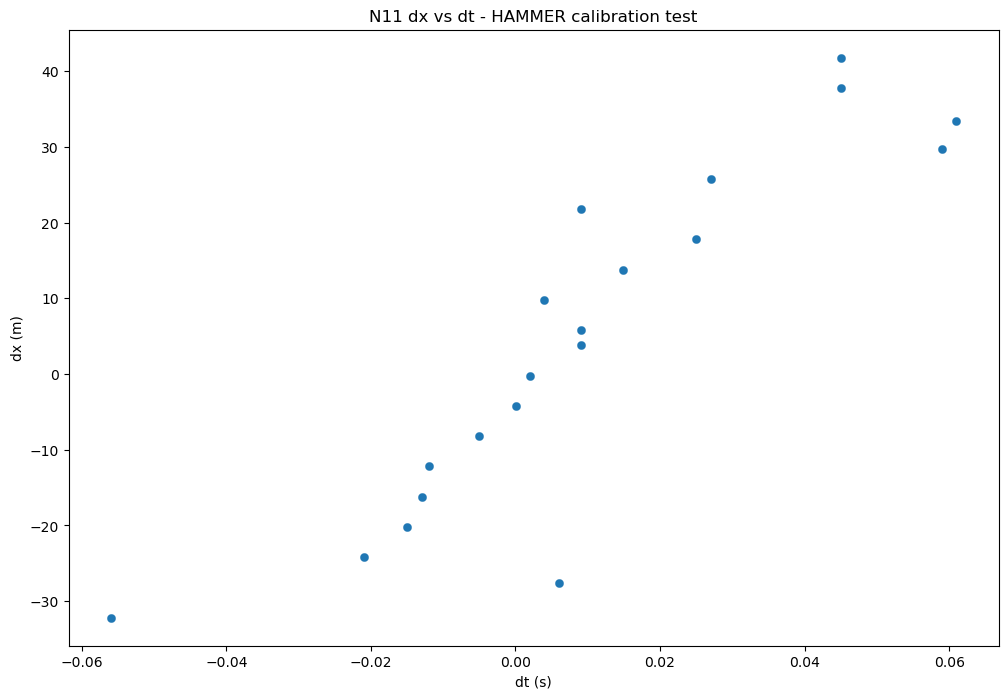

In [10]:
# 3. plot dx vs dt across whole calibration experiment

# compute velocity line of best fit
# v_p = dx/dt

# plot
plt.figure(figsize=(12,8))
plt.scatter(dt, dx, linewidths=0.2)
plt.xlabel("dt (s)")
plt.ylabel("dx (m)")
plt.title("N11 dx vs dt - HAMMER calibration test")
plt.savefig(r"D:\arrival_markers\arrival_plots\N11_hammer_dx_vs_dt_test.png")
plt.show()


In [ ]:
# 4. compute velocity of each strike individually

# v_1 = dx_1/dt_1, ..., v_n = dx_n/dt_n

In [ ]:
# 5. compute avg velocity of each strike location

# compute avg time at each matching distance (e.g. t_avg at x1, x2, x3, etc)
# v_avg = dx/dt_avg